# Learning Activity 4: Modeling and Commercial Strategy (Actividad 4: Modelado y Estrategia Comercial)
**Business Case:** North Quay Gifts | **Dataset:** Online Retail II
**CRISP-DM Phases:** Modeling and Evaluation

**Team Members:**
- Russel Emmanuel Ku Aguilar (ID: 2309131)
- Damian Nicolas Sanchez Novelo (ID: 2109134)
- Jonathan Abisai Velasco Martín (ID: 2309060)
- Ángel Rivaldo Canché Chuc (ID: 2309030)
- Bianca Alexandra Acosta Castellanos (ID: 2309001)

**Academic Advisor / Professor:** Didier Omar Gamboa Angulo (`didier.gamboa@upy.edu.mx`)
**Institution:** Faculty of Data Engineering, Universidad Politécnica de Yucatán (UPY)

---
### Scope and conventions
- **Route B** (selected in Activity 2): every monetary figure is **sales net of recorded credits**, in GBP. It is not profit.
- Inputs (built in Activities 2 and 3, not modified here):

| Section | Input | Period |
|---|---|---|
| I – Sales forecast | `../A-3-4_DataCleaning/outputs/indicadores_diarios.csv` | 604 observed trading days, 2009-12-01 to 2011-12-09 |
| II – Repurchase classification | `../A-3-5_DataConstruction/outputs/clientes_clasificacion.csv` | history 2011-01-02 to 2011-06-30, label 2011-07-01 to 2011-09-28 |
| III – Segmentation | `../A-3-5_DataConstruction/outputs/clientes_rfm.csv` | 2009-12-01 to 2011-12-09, reference 2011-12-10 |

- One global seed: `SEED = 42` for every split, tree and K-Means run.
- All forecast periods are in the future relative to the case history, which ends in December 2011; they are not current sales.
- The classification is a July 2011 snapshot and the segmentation uses information up to December 2011; they are two different
  pictures of the customer base and are not mixed.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, silhouette_score)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.cluster import KMeans
import sklearn
warnings.filterwarnings('ignore')

SEED = 42
ROUTE = 'B'
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'axes.edgecolor': '#333333', 'axes.linewidth': 0.8, 'font.size': 10})
pd.set_option('display.width', 200); pd.set_option('display.max_columns', None)
os.makedirs('figures', exist_ok=True); os.makedirs('outputs', exist_ok=True)
gbp = mticker.FuncFormatter(lambda x, p: f'£{x:,.0f}')
R = {'seed': SEED, 'route': ROUTE}
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| seed', SEED, '| route', ROUTE)

pandas 3.0.5 | scikit-learn 1.9.1 | seed 42 | route B


---
# Section I – Sales regression and forecast (Regresión y pronóstico de ventas)
**Question:** what sales can we expect, and how can that forecast support commercial planning?

### I.1 Design
- **Target:** daily `Revenue` (GBP, Route B net of credits). `TotalOrders` is used only for operational context, never as a predictor.
- **Time unit:** one **observed trading day**. The store has no records on most Sundays, on some Saturdays and during the
  Christmas closure; those dates are **not** filled with zeros because there is no evidence of zero sales (Activity 2).
- **Forecast type:** **one step ahead** — each forecast is issued at the close of an observed day for the **next observed
  trading day**. At issue time we know all revenue up to and including the issue day; once the next day is observed it is added
  to the history before forecasting the following one. No orders or units of the target day are used.
- **Test block:** the last **60 observed trading days** (2011-10-02 to 2011-12-09), kept untouched until the final evaluation.
- **Lags are in rows, not days:** `lag1` is the previous *observed* day, which can be 1–4 calendar days earlier (e.g., Friday →
  Monday). The feature `GapDays` (calendar days since the previous observed day) and day-of-week dummies make that explicit.

In [2]:
daily = pd.read_csv('../A-3-4_DataCleaning/outputs/indicadores_diarios.csv', parse_dates=['Date']).set_index('Date').sort_index()
print('Rows:', len(daily), '| first:', daily.index.min().date(), '| last:', daily.index.max().date())
print('Calendar days in range:', (daily.index.max() - daily.index.min()).days + 1, '→ observed days are', len(daily))
gaps = daily.index.to_series().diff().dt.days.value_counts().sort_index()
print('Gap between consecutive observed days (calendar days → count):', gaps.to_dict())
print('Observed days by weekday (0=Mon):', daily.index.dayofweek.value_counts().sort_index().to_dict())
display(daily.describe().round(2))

Rows: 604 | first: 2009-12-01 | last: 2011-12-09
Calendar days in range: 739 → observed days are 604
Gap between consecutive observed days (calendar days → count): {1.0: 495, 2.0: 103, 3.0: 1, 5.0: 2, 12.0: 2}
Observed days by weekday (0=Mon): {0: 94, 1: 104, 2: 104, 3: 103, 4: 99, 5: 1, 6: 99}


,TotalOrders,TotalUnits,Revenue
count,604.00,604.00,604.00
mean,66.35,17762.13,31479.86
std,24.78,11650.88,16514.55
min,11.00,-63859.00,-1727.65
25%,49.00,11411.50,20944.03
50%,63.00,15667.50,27846.39
75%,80.00,21512.25,39105.89
max,153.00,122733.00,111958.62


In [3]:
s = daily['Revenue']
feat = pd.DataFrame(index=s.index)
feat['y'] = s
for k in (1, 2, 3, 5, 6):
    feat[f'Lag{k}'] = s.shift(k)                      # previous observed days (rows)
feat['RollMean5'] = s.shift(1).rolling(5).mean()      # mean of the 5 previous observed days
feat['RollMean20'] = s.shift(1).rolling(20).mean()    # ≈ previous 4 trading weeks
feat['RollMedian5'] = s.shift(1).rolling(5).median()
feat['GapDays'] = feat.index.to_series().diff().dt.days
feat['DayOfWeek'] = feat.index.dayofweek
feat['Month'] = feat.index.month
feat['DayOfYear'] = feat.index.dayofyear
feat['Trend'] = np.arange(len(feat))
feat = feat.dropna()                                   # first 20 observed days lack a full window
dow = pd.get_dummies(feat['DayOfWeek'].astype(pd.CategoricalDtype(range(7))), prefix='DOW').astype(float)
feat = pd.concat([feat, dow], axis=1)

TEST_N = 60
train, test = feat.iloc[:-TEST_N], feat.iloc[-TEST_N:]
print('Modelling rows:', len(feat), '| train:', train.index.min().date(), '→', train.index.max().date(), f'({len(train)})',
      '| test:', test.index.min().date(), '→', test.index.max().date(), f'({len(test)})')
DOW_COLS = list(dow.columns)
F_INITIAL = ['Lag1', 'Lag2', 'Lag5', 'RollMean5', 'RollMean20'] + DOW_COLS
F_ALT = F_INITIAL + ['Lag3', 'Lag6', 'RollMedian5', 'GapDays', 'Month', 'DayOfYear', 'Trend']
R['fc_design'] = dict(rows=len(daily), model_rows=len(feat), train=[str(train.index.min().date()), str(train.index.max().date()), len(train)],
                      test=[str(test.index.min().date()), str(test.index.max().date()), len(test)])

Modelling rows: 584 | train: 2009-12-23 → 2011-09-30 (524) | test: 2011-10-02 → 2011-12-09 (60)


### I.2 Candidates and selection inside the training block
| Role | Model | Features |
|---|---|---|
| Reference | **Naive**: next observed day = last observed value (`Lag1`) | — |
| Initial model | **Linear regression** (standardized inside a pipeline) | 2 lags, 3 recent means, day of week |
| Alternative | **Random forest** (300 trees) with a bounded search of `min_samples_leaf` ∈ {5, 10, 20} | initial features + more lags, gap, month, day of year, trend |

Selection uses **expanding-window time-series cross-validation inside the training block** (`TimeSeriesSplit`, 5 folds of 40
observed days). The scaler and every model are refit on the training part of each fold only. The configuration with the lowest
mean CV MAE is selected **before** looking at the test block.

In [4]:
def make_model(kind, leaf=None):
    if kind == 'Linear regression':
        return make_pipeline(StandardScaler(), LinearRegression())
    return RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, random_state=SEED, n_jobs=-1)

candidates = [('Naive (last value)', None, None, None), ('Linear regression', 'Linear regression', None, F_INITIAL)]
candidates += [(f'Random forest (leaf={l})', 'Random forest', l, F_ALT) for l in (5, 10, 20)]
tscv = TimeSeriesSplit(n_splits=5, test_size=40)
rows = []
for name, kind, leaf, cols in candidates:
    maes = []
    for a, b in tscv.split(train):
        A, V = train.iloc[a], train.iloc[b]
        if kind is None:
            p = V['Lag1'].values
        else:
            m = make_model(kind, leaf).fit(A[cols], A['y']); p = m.predict(V[cols])
        maes.append(mean_absolute_error(V['y'], p))
    rows.append(dict(Model=name, CV_MAE=np.mean(maes), CV_MAE_std=np.std(maes)))
cv_table = pd.DataFrame(rows).set_index('Model')
display(cv_table.round(0))
best_rf = cv_table.filter(like='Random forest', axis=0)['CV_MAE'].idxmin()
selected = cv_table.drop('Naive (last value)')['CV_MAE'].idxmin()
print('Best random-forest configuration:', best_rf)
print('SELECTED by training CV (before test):', selected)
R['fc_cv'] = {k: float(v) for k, v in cv_table['CV_MAE'].items()}
R['fc_selected'] = selected; R['fc_best_rf'] = best_rf

,CV_MAE,CV_MAE_std
Model,,
Naive (last value),13012.0,2762.0
Linear regression,7937.0,2227.0
Random forest (leaf=5),8145.0,2093.0
Random forest (leaf=10),8244.0,1937.0
Random forest (leaf=20),8333.0,1841.0


Best random-forest configuration: Random forest (leaf=5)
SELECTED by training CV (before test): Linear regression


### I.3 Final evaluation on the test block (same 60 dates for every model)
Each model is refit once on the full training block. In the test block each forecast uses only revenue observed up to the
issue day (one step ahead).

In [5]:
leaf_rf = int(best_rf.split('=')[1].rstrip(')'))
fits = {'Linear regression': make_model('Linear regression').fit(train[F_INITIAL], train['y']),
        best_rf: make_model('Random forest', leaf_rf).fit(train[F_ALT], train['y'])}
pred = pd.DataFrame({'Actual': test['y'], 'Naive (last value)': test['Lag1'],
                     'Linear regression': fits['Linear regression'].predict(test[F_INITIAL]),
                     best_rf: fits[best_rf].predict(test[F_ALT])}, index=test.index)

def metrics(y, p):
    return dict(MAE=mean_absolute_error(y, p), RMSE=mean_squared_error(y, p) ** 0.5, R2=r2_score(y, p))
ev = pd.DataFrame({m: metrics(pred['Actual'], pred[m]) for m in pred.columns if m != 'Actual'}).T
ev['MAE vs naive %'] = 100 * (ev['MAE'] - ev.loc['Naive (last value)', 'MAE']) / ev.loc['Naive (last value)', 'MAE']
ev['RMSE vs naive %'] = 100 * (ev['RMSE'] - ev.loc['Naive (last value)', 'RMSE']) / ev.loc['Naive (last value)', 'RMSE']
display(ev.round(3))
train_fit = metrics(train['y'], fits[selected].predict(train[F_INITIAL if selected == 'Linear regression' else F_ALT]))
print('Selected model on training data:', {k: round(v, 3) for k, v in train_fit.items()})
pred.round(2).rename_axis('Date').to_csv('outputs/forecast_test_predictions.csv')
R['fc_test'] = {m: {k: float(v) for k, v in r.items()} for m, r in ev.iterrows()}
R['fc_train_selected'] = {k: float(v) for k, v in train_fit.items()}
R['fc_test_stats'] = dict(mean_rev=float(test['y'].mean()), total=float(test['y'].sum()), mean_orders=float(daily.loc[test.index, 'TotalOrders'].mean()),
                          rev_per_order=float(test['y'].sum() / daily.loc[test.index, 'TotalOrders'].sum()))

,MAE,RMSE,R2,MAE vs naive %,RMSE vs naive %
Naive (last value),18359.952,23954.148,-0.728,0.000,0.000
Linear regression,11451.269,15580.404,0.269,-37.629,-34.957
Random forest (leaf=5),10158.306,14003.234,0.409,-44.671,-41.542


Selected model on training data: {'MAE': 8147.147, 'RMSE': 11436.582, 'R2': 0.406}


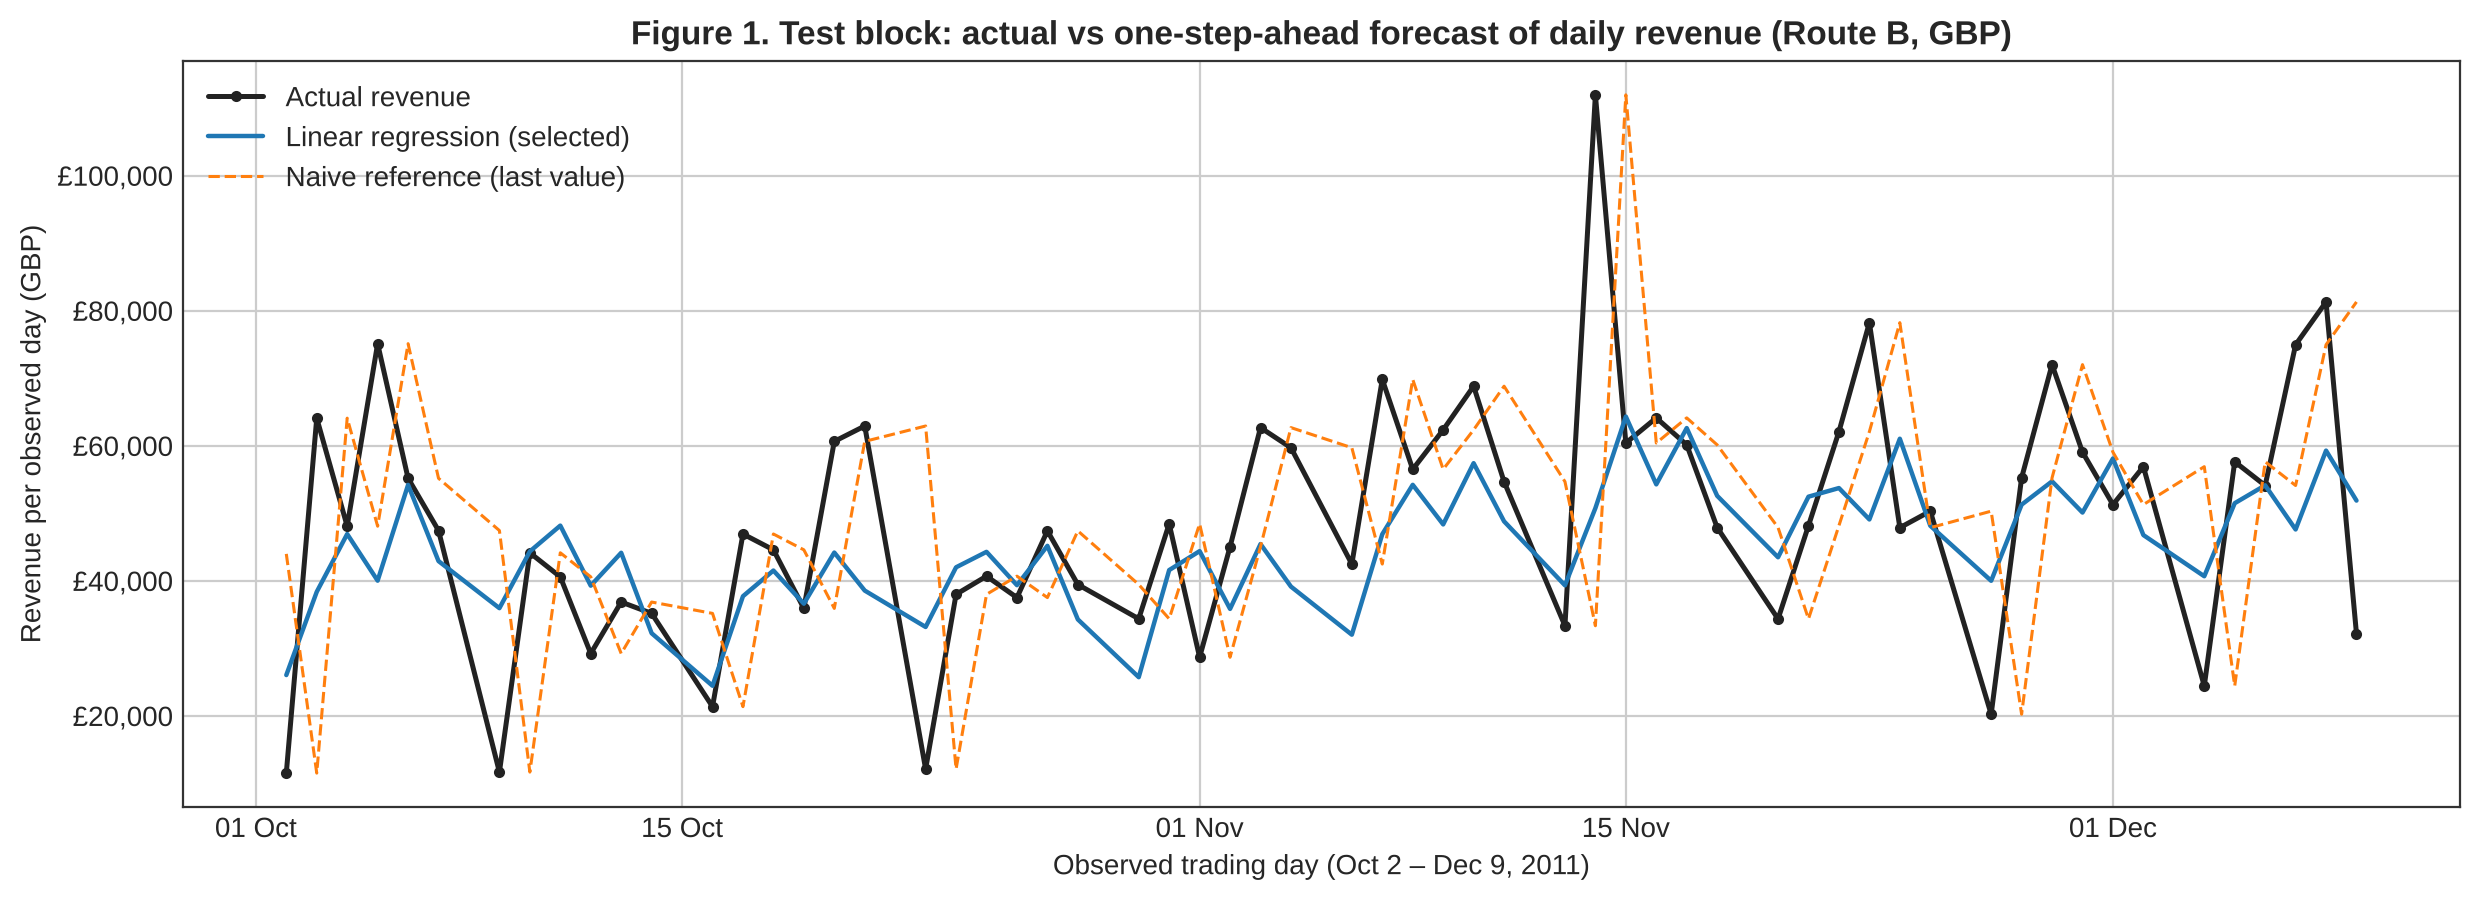

In [6]:
fig, ax = plt.subplots(figsize=(12.5, 4.6), dpi=200)
ax.plot(pred.index, pred['Actual'], color='#222222', lw=1.8, marker='o', ms=3, label='Actual revenue')
ax.plot(pred.index, pred[selected], color='#1f77b4', lw=1.6, label=f'{selected} (selected)')
ax.plot(pred.index, pred['Naive (last value)'], color='#ff7f0e', lw=1.1, ls='--', label='Naive reference (last value)')
ax.set_title('Figure 1. Test block: actual vs one-step-ahead forecast of daily revenue (Route B, GBP)', fontweight='bold')
ax.set_ylabel('Revenue per observed day (GBP)'); ax.set_xlabel('Observed trading day (Oct 2 – Dec 9, 2011)')
ax.yaxis.set_major_formatter(gbp); ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax.legend(loc='upper left'); fig.tight_layout(); fig.savefig('figures/fig1_forecast_test.png', bbox_inches='tight'); plt.show()

### I.4 The two largest errors of the selected model and their planning meaning

In [7]:
err = pred[['Actual', selected, 'Naive (last value)']].copy()
err['Error'] = err[selected] - err['Actual']                 # positive = over-forecast
err['AbsError'] = err['Error'].abs()
err['Orders'] = daily.loc[err.index, 'TotalOrders']
top2 = err.sort_values('AbsError', ascending=False).head(2)
display(top2.round(2))
rpo = R['fc_test_stats']['rev_per_order']
top2_out = []
for d_, r in top2.iterrows():
    kind = 'over-forecast' if r.Error > 0 else 'under-forecast'
    print(f"{d_.date()} ({d_.day_name()}): {kind} of £{abs(r.Error):,.0f} = {100*abs(r.Error)/R['fc_test_stats']['mean_rev']:.0f}% of an average test day "
          f"≈ {abs(r.Error)/rpo:.0f} orders at the test-period average of £{rpo:,.0f} per order")
    top2_out.append(dict(date=str(d_.date()), dow=d_.day_name(), actual=float(r.Actual), forecast=float(r[selected]), error=float(r.Error), orders=int(r.Orders)))
R['fc_top2'] = top2_out
# Context for the largest error: what happened on that date (Activity 2 found a large same-day cancellation on 2011-12-09)
display(daily.loc[top2.index])
bias = err['Error'].mean()
print(f"Mean error (bias) of the selected model on test: £{bias:,.0f} per day ({'over' if bias > 0 else 'under'}-forecast on average); "
      f"share of days under-forecast: {100 * (err['Error'] < 0).mean():.0f}%")
R['fc_bias'] = dict(mean=float(bias), under_share=float((err['Error'] < 0).mean()))

,Actual,Linear regression,Naive (last value),Error,AbsError,Orders
Date,,,,,,
2011-11-14,111958.62,50759.18,33341.65,-61199.44,61199.44,107
2011-10-05,75111.57,40019.93,48082.73,-35091.64,35091.64,96


2011-11-14 (Monday): under-forecast of £61,199 = 124% of an average test day ≈ 116 orders at the test-period average of £526 per order
2011-10-05 (Wednesday): under-forecast of £35,092 = 71% of an average test day ≈ 67 orders at the test-period average of £526 per order


,TotalOrders,TotalUnits,Revenue
Date,,,
2011-11-14,107,47043,111958.62
2011-10-05,96,46045,75111.57


Mean error (bias) of the selected model on test: £-4,111 per day (under-forecast on average); share of days under-forecast: 58%


In [8]:
# Planning view: weekly totals (ISO weeks, test block) – sums of the one-step forecasts vs actual
wk = pred.groupby(pred.index.to_period('W-SUN')).agg(Days=('Actual', 'size'), Actual=('Actual', 'sum'), Forecast=(selected, 'sum'), Naive=('Naive (last value)', 'sum'))
wk['Error %'] = 100 * (wk['Forecast'] - wk['Actual']) / wk['Actual']
wk['Naive error %'] = 100 * (wk['Naive'] - wk['Actual']) / wk['Actual']
display(wk.round(1))
print('Note: the first and last weeks are partial (test starts on a Sunday and ends on Friday Dec 9).')
R['fc_weekly_mape'] = dict(model=float(wk['Error %'].abs().mean()), naive=float(wk['Naive error %'].abs().mean()))
R['fc_total'] = dict(actual=float(pred['Actual'].sum()), model=float(pred[selected].sum()), naive=float(pred['Naive (last value)'].sum()))
full = wk[wk.Days >= 6]
peak = full.loc[[p for p in full.index if pd.Timestamp('2011-10-31') <= p.start_time <= pd.Timestamp('2011-11-14')]]
R['fc_weeks'] = dict(total_gap_pct=float(100 * (pred[selected].sum() - pred['Actual'].sum()) / pred['Actual'].sum()),
                     full_weeks_mean_gap_pct=float(full['Error %'].mean()), peak_min=float(peak['Error %'].max()), peak_max=float(peak['Error %'].min()),
                     weeks=[dict(week=str(p.start_time.date()), days=int(r.Days), actual=float(r.Actual), forecast=float(r.Forecast), gap=float(r['Error %'])) for p, r in wk.iterrows()])
print(f"Whole test block: forecast {100 * (pred[selected].sum() / pred['Actual'].sum() - 1):.1f}% vs actual; mean gap of full weeks {full['Error %'].mean():.1f}%; "
      f"peak weeks Oct 31 – Nov 20: {peak['Error %'].max():.1f}% to {peak['Error %'].min():.1f}%")

,Days,Actual,Forecast,Naive,Error %,Naive error %
Date,,,,,,
2011-09-26/2011-10-02,1,11520.6,26039.3,43982.8,126.0,281.8
2011-10-03/2011-10-09,6,301565.4,258376.6,301415.1,-14.3,-0.0
2011-10-10/2011-10-16,6,207345.6,232632.3,197654.1,12.2,-4.7
2011-10-17/2011-10-23,6,263103.8,231735.8,272346.4,-11.9,3.5
2011-10-24/2011-10-30,6,237399.1,230821.0,215146.9,-2.8,-9.4
2011-10-31/2011-11-06,6,287017.9,238414.7,278910.3,-16.9,-2.8
2011-11-07/2011-11-13,6,345524.7,295012.0,354662.7,-14.6,2.6
2011-11-14/2011-11-20,6,378849.8,328040.2,377838.8,-13.4,-0.3
2011-11-21/2011-11-27,6,306886.9,304468.8,320999.8,-0.8,4.6


Note: the first and last weeks are partial (test starts on a Sunday and ends on Friday Dec 9).
Whole test block: forecast -8.3% vs actual; mean gap of full weeks -7.6%; peak weeks Oct 31 – Nov 20: -13.4% to -16.9%


**Interpretation (Route B, GBP).**
- **Selection:** training CV picks the **linear regression** (CV MAE £7,937 vs £8,145 for the best random forest and £13,012 for
  the naive reference).
- **Test vs reference:** on the same 60 test days it cuts MAE by 37.6% (£11,451 vs £18,360) and RMSE by 35.0% (£15,580 vs £23,954),
  with R² = 0.27; the naive reference has R² = −0.73. The random forest scores better on test (MAE £10,158), but it lost in CV, so the
  selection is not changed after seeing the test; it is a candidate to re-validate with more data.
- **Bias:** the model under-forecasts 58% of test days (mean error −£4,111 per day) and weekly totals were 13–17% low in the three peak weeks
  (Oct 31 – Nov 20) and 8.3% low over the whole test block. It smooths daily noise but lags the seasonal ramp. Summed over a week, the naive forecast is close to the actual
  total only because it repeats each day's value one day later.
- **Largest errors:** Monday 2011-11-14 (actual £111,959, forecast £50,759: −£61,199, about 116 orders at £526 per order) and
  Wednesday 2011-10-05 (−£35,092, about 67 orders). Both are peak days that a staffing plan based on the forecast would have
  under-resourced.
- **Over vs under:** in October–December under-forecasting is the costlier error (stock-outs and late dispatch of Christmas items
  that cannot be sold after the season), so the forecast should be used as a daily baseline planned at **forecast + 10% in October–December and + 15% in
  November**, reviewed weekly (the buffer is sized from the 8.3% total and 13–17% peak-week shortfalls above).
- **Information that would help:** wholesale order pipeline / pre-orders, a promotions calendar and more years of history to
  estimate the Q4 seasonality directly.

---
# Section II – Classification and repurchase strategies (Clasificación y estrategias de recompra)
**Question:** which profiles are more or less likely to repurchase, and which commercial actions should be tested?

Input: `clientes_clasificacion.csv` (July 2011 snapshot). Predictors: `RecencyDays`, `TotalOrders`, `TotalSpent` (180 days before
2011-07-01, Route B). Target: `Repurchase90Days` (1 = at least one valid purchase in the next 90 days). `CustomerID` is an
identifier only. **Positive class = 1.**

In [9]:
cls = pd.read_csv('../A-3-5_DataConstruction/outputs/clientes_clasificacion.csv')
FEATS = ['RecencyDays', 'TotalOrders', 'TotalSpent']
X, y = cls[FEATS], cls['Repurchase90Days']
bal = y.value_counts().sort_index().to_frame('Customers'); bal['%'] = (100 * bal['Customers'] / len(y)).round(2)
display(bal)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
split = pd.DataFrame({'Train': y_tr.value_counts().sort_index(), 'Test': y_te.value_counts().sort_index()})
split.loc['% class 1'] = [100 * y_tr.mean(), 100 * y_te.mean()]
display(split.round(2))
R['cl_balance'] = {str(k): int(v) for k, v in y.value_counts().sort_index().items()}
R['cl_split'] = dict(train=len(y_tr), test=len(y_te), train_pos=float(y_tr.mean()), test_pos=float(y_te.mean()))

,Customers,%
Repurchase90Days,,
0,1315,48.27
1,1409,51.73


,Train,Test
Repurchase90Days,,
0,1052.00,263.00
1,1127.00,282.00
% class 1,51.72,51.74


### II.1 Main metric
The two actions (a loyalty offer for likely repurchasers and a reactivation contact for unlikely ones) both need the model to
separate the classes in a balanced way: missing repurchasers wastes the loyalty audience and contacting non-repurchasers wastes
budget. With almost balanced classes, the **main selection metric is F1 of class 1**; Precision and Recall of both classes are
reported to size each audience.

### II.2 Initial tree and bounded search
- **Initial tree:** `DecisionTreeClassifier(random_state=42)` with default (unbounded) depth.
- **Search:** `max_depth` ∈ {3, 4, 5} × `min_samples_leaf` ∈ {20, 50, 100}, 5-fold **stratified** CV inside training
  (`shuffle=True, random_state=42`), scoring = F1 (class 1). The best combination is refit on all training data (`refit=True`).

In [10]:
tree0 = DecisionTreeClassifier(random_state=SEED).fit(X_tr, y_tr)
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                    {'max_depth': [3, 4, 5], 'min_samples_leaf': [20, 50, 100]},
                    scoring='f1', cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED), refit=True).fit(X_tr, y_tr)
res = pd.DataFrame(grid.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score']]
display(res.sort_values('rank_test_score').round(4))
tree1 = grid.best_estimator_
print('Selected parameters:', grid.best_params_, '| mean CV F1:', round(grid.best_score_, 4))
print('Initial tree depth:', tree0.get_depth(), '| leaves:', tree0.get_n_leaves(), '|| selected tree depth:', tree1.get_depth(), '| leaves:', tree1.get_n_leaves())
R['cl_grid'] = dict(best=grid.best_params_, cv_f1=float(grid.best_score_), init_depth=int(tree0.get_depth()), init_leaves=int(tree0.get_n_leaves()),
                    sel_depth=int(tree1.get_depth()), sel_leaves=int(tree1.get_n_leaves()))

,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
4,4,50,0.6815,0.0092,1
0,3,20,0.6810,0.0290,2
5,4,100,0.6795,0.0173,3
2,3,100,0.6795,0.0297,4
3,4,20,0.6794,0.0090,5
1,3,50,0.6772,0.0252,6
8,5,100,0.6666,0.0285,7
6,5,20,0.6649,0.0205,8
7,5,50,0.6631,0.0183,9


Selected parameters: {'max_depth': 4, 'min_samples_leaf': 50} | mean CV F1: 0.6815
Initial tree depth: 30 | leaves: 726 || selected tree depth: 4 | leaves: 15


Accuracy  Precision  Recall     F1  Precision0  Recall0
Initial tree  Train     1.000      1.000   1.000  1.000       1.000    1.000
              Test      0.618      0.624   0.660  0.641       0.611    0.574
Selected tree Train     0.702      0.724   0.686  0.704       0.681    0.720
              Test      0.716      0.759   0.660  0.706       0.680    0.776

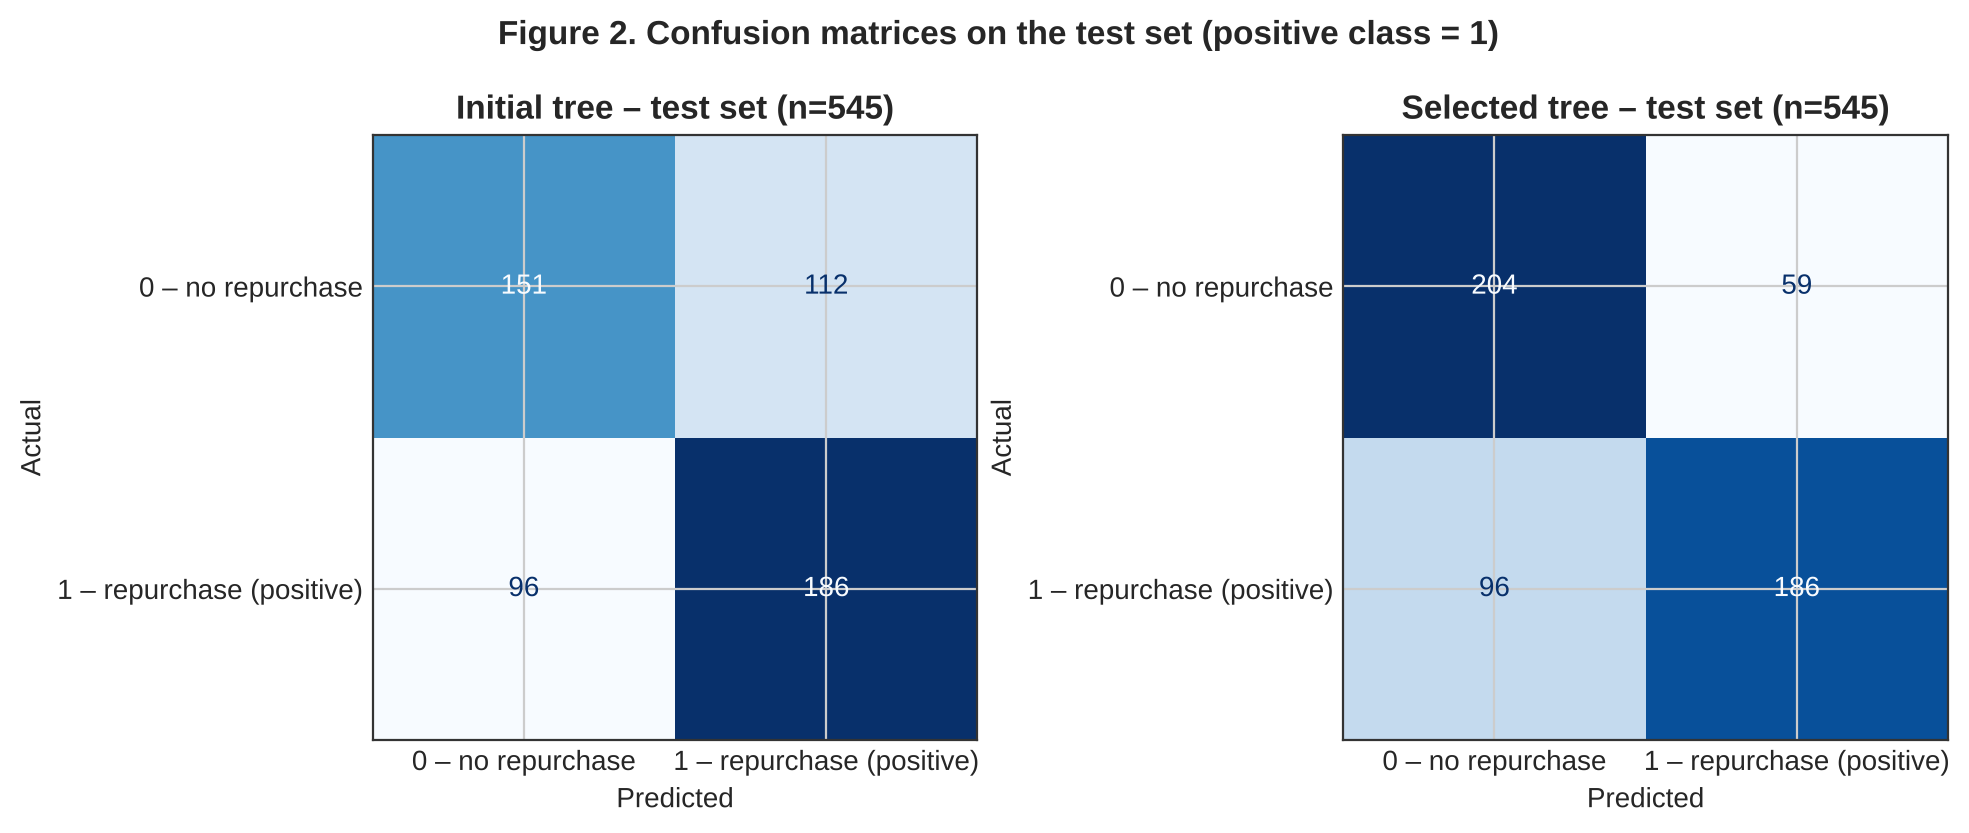

In [11]:
def scores(model, X_, y_):
    p = model.predict(X_)
    return dict(Accuracy=accuracy_score(y_, p), Precision=precision_score(y_, p), Recall=recall_score(y_, p), F1=f1_score(y_, p),
                Precision0=precision_score(y_, p, pos_label=0), Recall0=recall_score(y_, p, pos_label=0))
comp = pd.DataFrame({('Initial tree', 'Train'): scores(tree0, X_tr, y_tr), ('Initial tree', 'Test'): scores(tree0, X_te, y_te),
                     ('Selected tree', 'Train'): scores(tree1, X_tr, y_tr), ('Selected tree', 'Test'): scores(tree1, X_te, y_te)}).T
display(comp.round(3))
R['cl_metrics'] = {f'{a}|{b}': {k: float(v) for k, v in r.items()} for (a, b), r in comp.iterrows()}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), dpi=200)
cms = {}
for ax, (nm, m) in zip(axes, [('Initial tree', tree0), ('Selected tree', tree1)]):
    cm = confusion_matrix(y_te, m.predict(X_te), labels=[0, 1]); cms[nm] = cm.tolist()
    ConfusionMatrixDisplay(cm, display_labels=['0 – no repurchase', '1 – repurchase (positive)']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(f'{nm} – test set (n={len(y_te)})', fontweight='bold'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
fig.suptitle('Figure 2. Confusion matrices on the test set (positive class = 1)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig2_confusion_matrices.png', bbox_inches='tight'); plt.show()
R['cl_cm'] = cms

**Train vs Test.** The initial tree memorizes the training data (Train metrics = 1.0) and drops sharply on Test: clear
overfitting. The selected tree has similar Train and Test metrics, so its rules generalize. The selection was fixed before
reading the test results and is not changed afterwards.

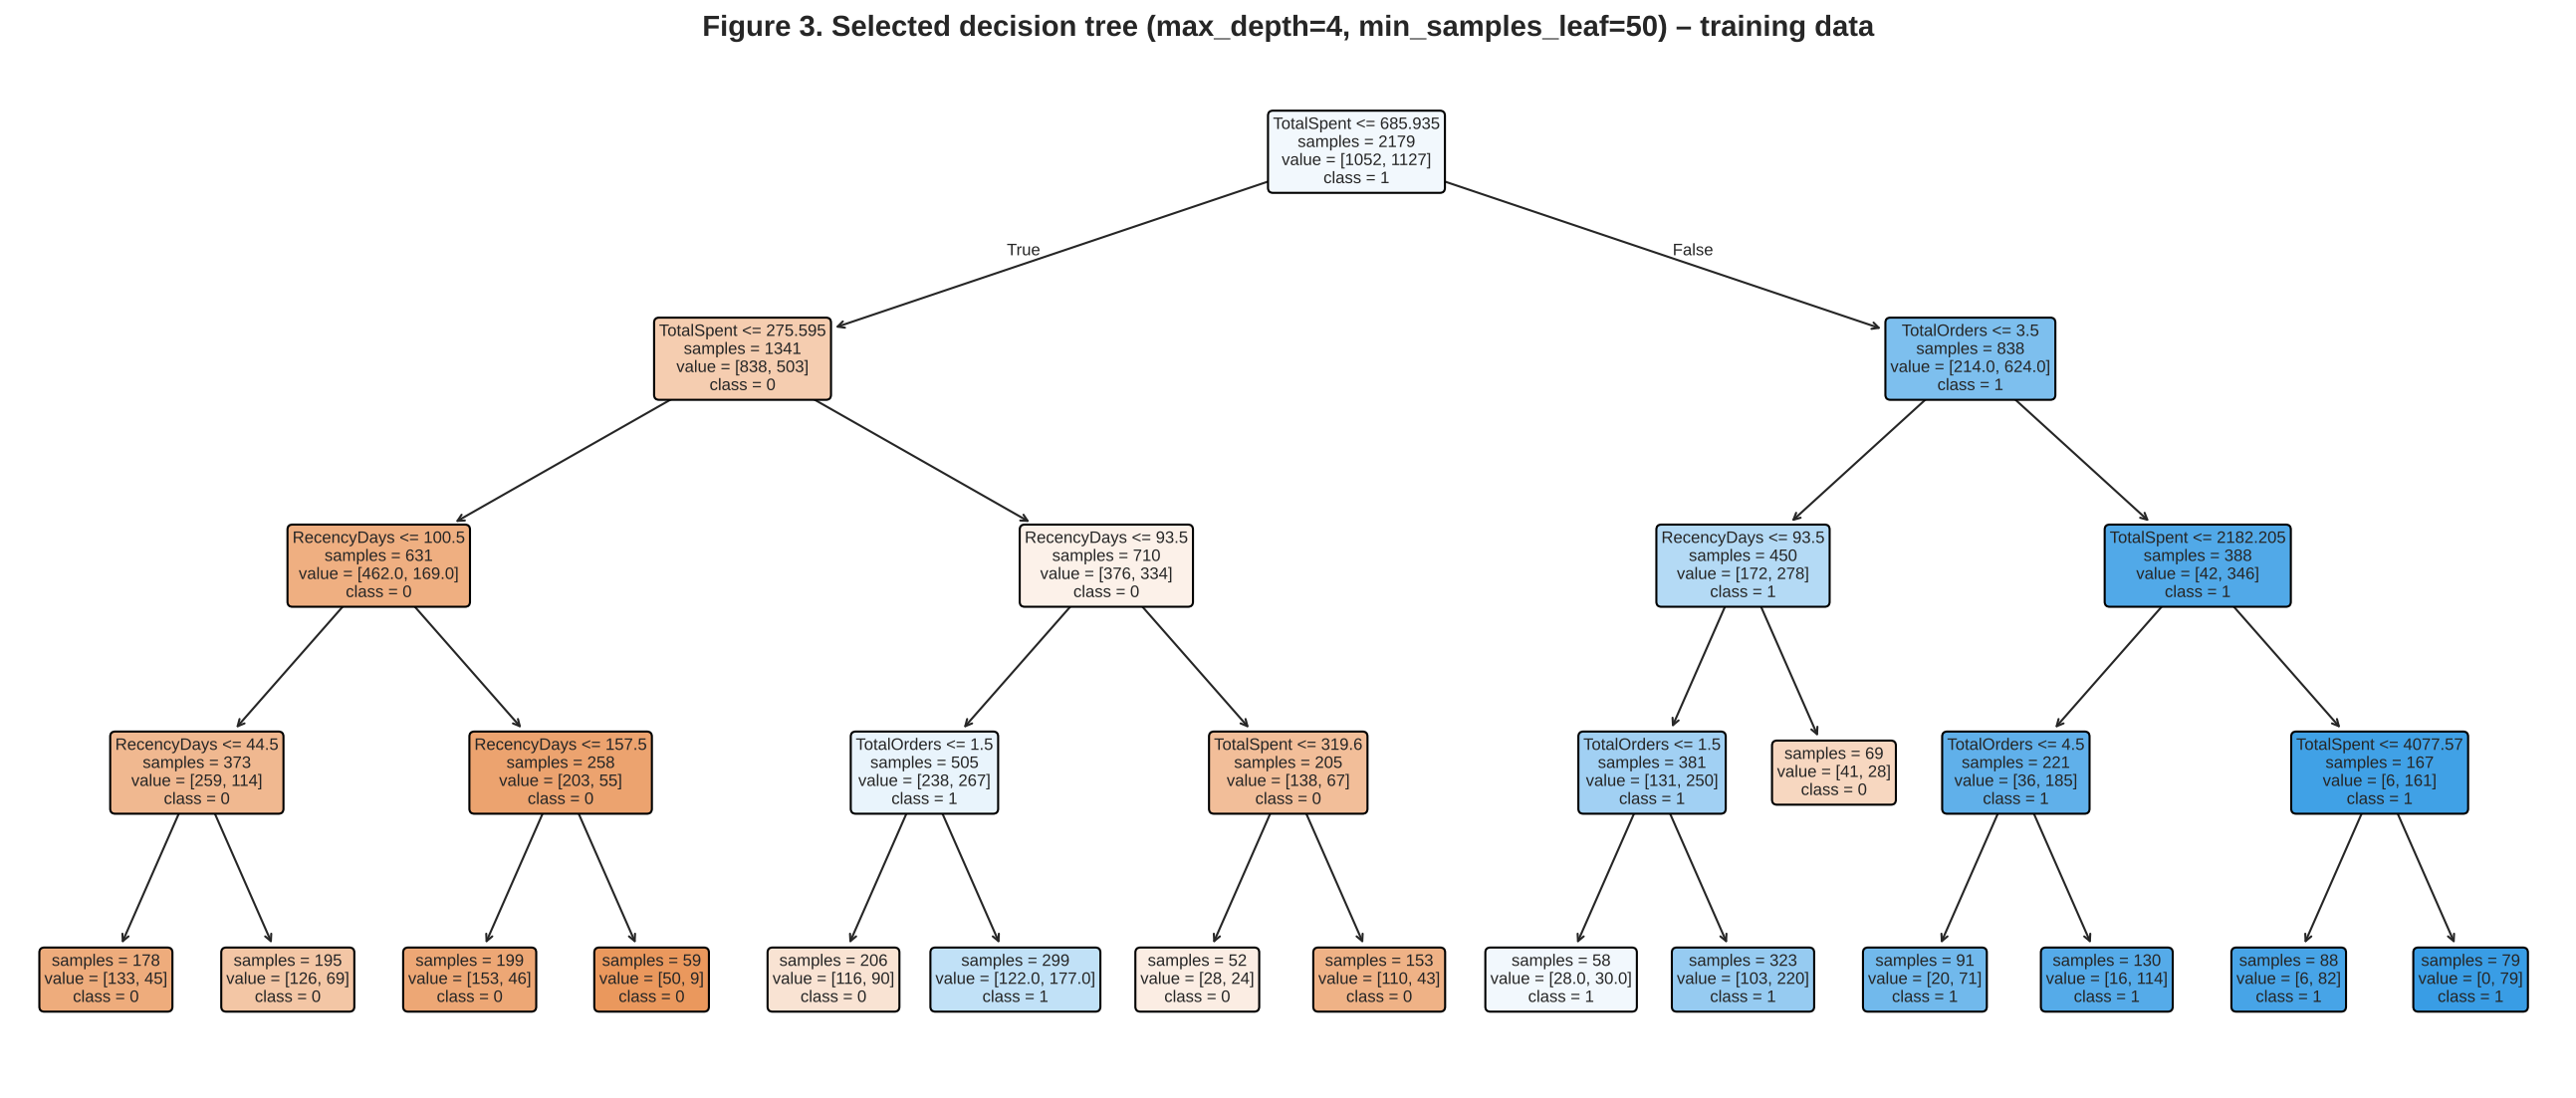

|--- TotalSpent <= 685.93
|   |--- TotalSpent <= 275.60
|   |   |--- RecencyDays <= 100.50
|   |   |   |--- RecencyDays <= 44.50
|   |   |   |   |--- weights: [133.00, 45.00] class: 0
|   |   |   |--- RecencyDays >  44.50
|   |   |   |   |--- weights: [126.00, 69.00] class: 0
|   |   |--- RecencyDays >  100.50
|   |   |   |--- RecencyDays <= 157.50
|   |   |   |   |--- weights: [153.00, 46.00] class: 0
|   |   |   |--- RecencyDays >  157.50
|   |   |   |   |--- weights: [50.00, 9.00] class: 0
|   |--- TotalSpent >  275.60
|   |   |--- RecencyDays <= 93.50
|   |   |   |--- TotalOrders <= 1.50
|   |   |   |   |--- weights: [116.00, 90.00] class: 0
|   |   |   |--- TotalOrders >  1.50
|   |   |   |   |--- weights: [122.00, 177.00] class: 1
|   |   |--- RecencyDays >  93.50
|   |   |   |--- TotalSpent <= 319.60
|   |   |   |   |--- weights: [28.00, 24.00] class: 0
|   |   |   |--- TotalSpent >  319.60
|   |   |   |   |--- weights: [110.00, 43.00] class: 0
|--- TotalSpent >  685.93
|   |---

In [12]:
fig, ax = plt.subplots(figsize=(22, 9), dpi=150)
plot_tree(tree1, feature_names=FEATS, class_names=['0', '1'], filled=True, rounded=True, proportion=False, impurity=False, fontsize=8, ax=ax)
ax.set_title('Figure 3. Selected decision tree (max_depth=%d, min_samples_leaf=%d) – training data' % (tree1.max_depth, tree1.min_samples_leaf), fontweight='bold', fontsize=14)
fig.savefig('figures/fig3_selected_tree.png', bbox_inches='tight'); plt.show()
print(export_text(tree1, feature_names=FEATS, show_weights=True))

### II.3 Complete rules (leaves) with training and test behaviour
Each leaf is a complete rule. Rules are chosen from **training** figures (largest leaves with the highest and lowest repurchase
rates, at least 100 training customers); their test behaviour is shown only as a check.

In [13]:
t = tree1.tree_
def paths(node=0, conds=()):
    if t.children_left[node] == -1:
        yield node, conds; return
    f, thr = FEATS[t.feature[node]], t.threshold[node]
    yield from paths(t.children_left[node], conds + (f'{f} <= {thr:,.2f}',))
    yield from paths(t.children_right[node], conds + (f'{f} > {thr:,.2f}',))

def simplify(conds):
    lo, hi = {}, {}
    for c in conds:
        f, op, v = c.split(' ')[0], c.split(' ')[1], float(c.split(' ')[2].replace(',', ''))
        if op == '<=': hi[f] = min(hi.get(f, np.inf), v)
        else: lo[f] = max(lo.get(f, -np.inf), v)
    out = []
    for f in FEATS:
        if f in lo and f in hi: out.append(f'{lo[f]:,.2f} < {f} <= {hi[f]:,.2f}')
        elif f in lo: out.append(f'{f} > {lo[f]:,.2f}')
        elif f in hi: out.append(f'{f} <= {hi[f]:,.2f}')
    return ' AND '.join(out)

leaf_tr, leaf_te = tree1.apply(X_tr), tree1.apply(X_te)
rules = []
for node, conds in paths():
    mtr, mte = leaf_tr == node, leaf_te == node
    rules.append(dict(Leaf=node, Rule=simplify(conds), TrainCustomers=int(mtr.sum()), TrainRepurchase=float(y_tr[mtr].mean()),
                      TestCustomers=int(mte.sum()), TestRepurchase=float(y_te[mte].mean()) if mte.sum() else np.nan, Predicted=int(tree1.predict(X_tr[mtr].head(1))[0])))
rules = pd.DataFrame(rules).sort_values('TrainRepurchase', ascending=False)
pd.set_option('display.max_colwidth', 120)
display(rules.round(3))
big = rules[rules.TrainCustomers >= 100]
rule_loyal = big.iloc[0]; rule_react = big.iloc[-1]
for lbl, r in [('LOYALTY rule (highest repurchase)', rule_loyal), ('REACTIVATION rule (lowest repurchase)', rule_react)]:
    print(f"\n{lbl}: IF {r.Rule}\n  train: {r.TrainCustomers} customers, {100*r.TrainRepurchase:.1f}% repurchased | test: {r.TestCustomers} customers, {100*r.TestRepurchase:.1f}% repurchased")
    sub = X_tr[leaf_tr == r.Leaf]
    print('  training medians – RecencyDays %.0f, TotalOrders %.0f, TotalSpent £%.0f' % (sub.RecencyDays.median(), sub.TotalOrders.median(), sub.TotalSpent.median()))
R['cl_rules'] = rules.to_dict('records')
R['cl_rule_loyal'] = rule_loyal.to_dict(); R['cl_rule_react'] = rule_react.to_dict()
R['cl_base_rate'] = float(y_tr.mean())

,Leaf,Rule,TrainCustomers,TrainRepurchase,TestCustomers,TestRepurchase,Predicted
14,28,"TotalOrders > 3.50 AND TotalSpent > 4,077.57",79,1.000,9,1.000,1
13,27,"TotalOrders > 3.50 AND 2,182.20 < TotalSpent <= 4,077.57",88,0.932,29,0.897,1
12,25,"TotalOrders > 4.50 AND 685.93 < TotalSpent <= 2,182.20",130,0.877,29,0.931,1
11,24,"3.50 < TotalOrders <= 4.50 AND 685.93 < TotalSpent <= 2,182.20",91,0.780,23,0.826,1
9,20,RecencyDays <= 93.50 AND 1.50 < TotalOrders <= 3.50 AND TotalSpent > 685.93,323,0.681,78,0.808,1
5,12,RecencyDays <= 93.50 AND TotalOrders > 1.50 AND 275.60 < TotalSpent <= 685.93,299,0.592,66,0.576,1
8,19,RecencyDays <= 93.50 AND TotalOrders <= 1.50 AND TotalSpent > 685.93,58,0.517,11,0.364,1
6,14,RecencyDays > 93.50 AND 275.60 < TotalSpent <= 319.60,52,0.462,8,0.250,0
4,11,RecencyDays <= 93.50 AND TotalOrders <= 1.50 AND 275.60 < TotalSpent <= 685.93,206,0.437,71,0.380,0
10,21,RecencyDays > 93.50 AND TotalOrders <= 3.50 AND TotalSpent > 685.93,69,0.406,21,0.619,0



LOYALTY rule (highest repurchase): IF TotalOrders > 4.50 AND 685.93 < TotalSpent <= 2,182.20
  train: 130 customers, 87.7% repurchased | test: 29 customers, 93.1% repurchased
  training medians – RecencyDays 17, TotalOrders 6, TotalSpent £1545

REACTIVATION rule (lowest repurchase): IF 100.50 < RecencyDays <= 157.50 AND TotalSpent <= 275.60
  train: 199 customers, 23.1% repurchased | test: 46 customers, 23.9% repurchased
  training medians – RecencyDays 123, TotalOrders 1, TotalSpent £155


### II.4 Audiences, errors and metric for each action
- **Loyalty audience:** customers predicted 1 → protect and grow repurchase (relevant metric: **Precision 1**, because benefits
  given to customers who would not buy anyway are wasted only partially, while offers to non-buyers are fully wasted).
- **Reactivation audience:** customers predicted 0 → contact before they lapse (relevant metrics: **Precision 0** and **Recall 0**).

In [14]:
cm = np.array(cms['Selected tree']); tn, fp, fn, tp = cm.ravel()
aud = dict(test_n=int(len(y_te)), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
           pred1=int(tp + fp), pred0=int(tn + fn), actual0=int(tn + fp), actual1=int(tp + fn),
           precision1=float(tp / (tp + fp)), recall1=float(tp / (tp + fn)), precision0=float(tn / (tn + fn)), recall0=float(tn / (tn + fp)))
print(f"Loyalty audience (predicted 1): {aud['pred1']} test customers; {aud['tp']} did repurchase (Precision 1 = {aud['precision1']:.3f}); "
      f"{aud['fp']} false positives = offers to customers who did not come back; {aud['fn']} false negatives = repurchasers left out of the loyalty list.")
print(f"Reactivation audience (predicted 0): {aud['pred0']} test customers; {aud['tn']} truly did not repurchase (Precision 0 = {aud['precision0']:.3f}); "
      f"{aud['fn']} repurchasers contacted unnecessarily; identifies {aud['tn']} of {aud['actual0']} non-repurchasers (Recall 0 = {aud['recall0']:.3f}); "
      f"{aud['fp']} non-repurchasers would remain unattended.")
# Scaled to the whole July population with the selected tree (descriptive, same model)
full_pred = tree1.predict(X)
R['cl_audience'] = aud
R['cl_population_pred'] = dict(pred1=int((full_pred == 1).sum()), pred0=int((full_pred == 0).sum()),
                               loyal_rule=int((tree1.apply(X) == rule_loyal.Leaf).sum()), react_rule=int((tree1.apply(X) == rule_react.Leaf).sum()))
print('Whole July population (2,724):', R['cl_population_pred'])

Loyalty audience (predicted 1): 245 test customers; 186 did repurchase (Precision 1 = 0.759); 59 false positives = offers to customers who did not come back; 96 false negatives = repurchasers left out of the loyalty list.
Reactivation audience (predicted 0): 300 test customers; 204 truly did not repurchase (Precision 0 = 0.680); 96 repurchasers contacted unnecessarily; identifies 204 of 263 non-repurchasers (Recall 0 = 0.776); 59 non-repurchasers would remain unattended.
Whole July population (2,724): {'pred1': 1313, 'pred0': 1411, 'loyal_rule': 159, 'react_rule': 245}


**Pilot design (to measure effect, not propensity).** Propensity is not causality: a high predicted repurchase does not show that
a promotion causes purchases. For the reactivation pilot we propose a **randomized holdout**: split the target audience at random
into a contacted group and a non-contacted control group with similar profiles.
- **Indicator:** 60-day reactivation rate = customers with ≥ 1 valid purchase within 60 days of the contact ÷ customers in the group.
- **Effect:** reactivation rate (contacted) − reactivation rate (control). Only this difference estimates what the campaign causes.
- Class 0 is **not** definitive churn (Activity 3: 35.1% of class-0 customers bought again between 2011-09-29 and 2011-12-09).

---
# Section III – Clustering and segmentation marketing (Clustering y marketing por segmentación)
**Question:** which customer segments exist and which marketing strategy fits each one?

Input: `clientes_rfm.csv` (5,878 customers; Route B; period to 2011-12-09; reference 2011-12-10). Features: Recency, Frequency,
Monetary. `CustomerID` and `Repurchase90Days` are **not** used.

,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.87,6.29,2781.74
std,209.35,13.01,13741.22
min,1.00,1.00,-10953.50
25%,26.00,1.00,329.68
50%,96.00,3.00,838.86
75%,380.00,7.00,2165.27
95%,626.00,21.00,8860.82
99%,727.00,46.00,26358.89
max,739.00,398.00,570380.61


Skewness: {'Recency': 0.89, 'Frequency': 12.64, 'Monetary': 26.72}


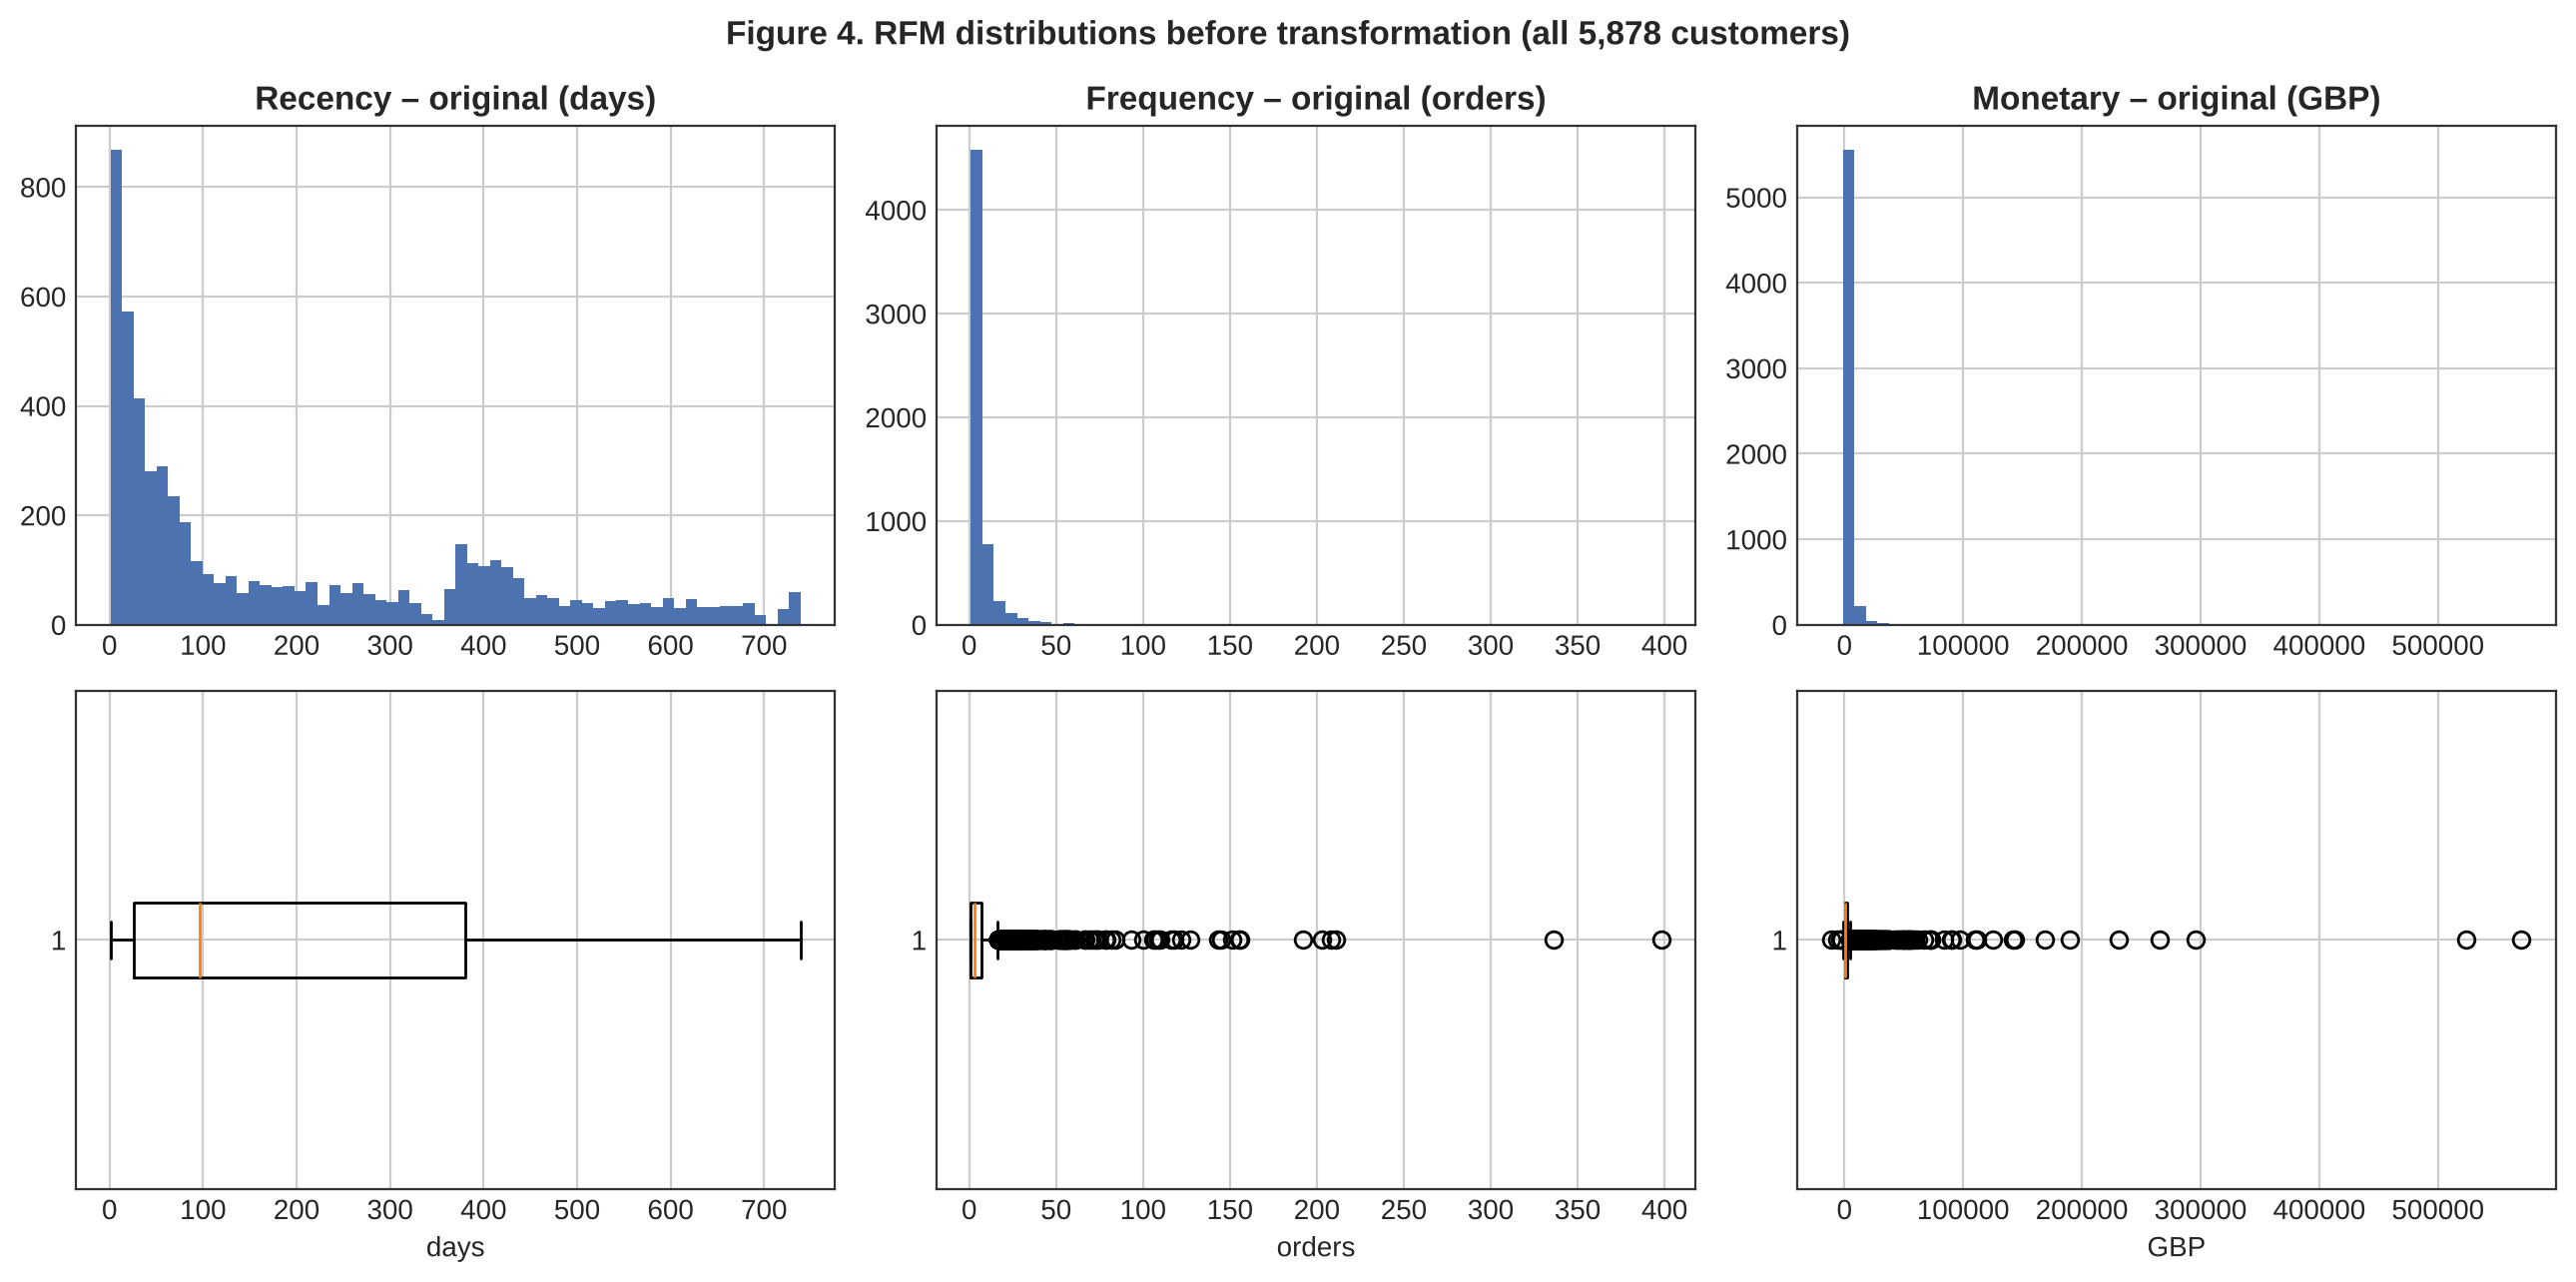

In [15]:
rfm = pd.read_csv('../A-3-5_DataConstruction/outputs/clientes_rfm.csv')
display(rfm[['Recency', 'Frequency', 'Monetary']].describe(percentiles=[.25, .5, .75, .95, .99]).round(2))
print('Skewness:', rfm[['Recency', 'Frequency', 'Monetary']].skew().round(2).to_dict())
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), dpi=200)
for i, (c, unit) in enumerate([('Recency', 'days'), ('Frequency', 'orders'), ('Monetary', 'GBP')]):
    axes[0, i].hist(rfm[c], bins=60, color='#4c72b0'); axes[0, i].set_title(f'{c} – original ({unit})', fontweight='bold')
    axes[1, i].boxplot(rfm[c], vert=False); axes[1, i].set_xlabel(unit)
fig.suptitle('Figure 4. RFM distributions before transformation (all 5,878 customers)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig4_rfm_distributions.png', bbox_inches='tight'); plt.show()

### III.1 Treatment of Monetary ≤ 0 and transformations
- Activity 3 kept **41 customers with Monetary ≤ 0** (21 at exactly £0, 20 negative) because Route B nets credits. A logarithm is
  not defined for them, and a signed log isolates them as an artificial micro-cluster of 41 customers. They are **excluded from
  K-Means** and reported as a separate review group ("net-credit accounts"), not converted to positive values.
- All three variables are strongly right-skewed (Frequency up to 398 orders, Monetary up to £570k), so K-Means on raw values
  would be driven by a few wholesale accounts. We use **natural logs** (all remaining values are > 0; Recency and Frequency ≥ 1),
  then **StandardScaler**. Outliers are kept: the log compresses them instead of deleting customers.
- Original values are kept for profiling.

In [16]:
excl = rfm[rfm.Monetary <= 0]
keep = rfm[rfm.Monetary > 0].copy()
R['cu_excluded'] = dict(n=int(len(excl)), pct=float(100 * len(excl) / len(rfm)), amount=float(excl.Monetary.sum()), zero=int((excl.Monetary == 0).sum()),
                        neg=int((excl.Monetary < 0).sum()), kept=int(len(keep)), total=int(len(rfm)),
                        kept_amount_share=float(100 * keep.Monetary.sum() / rfm.Monetary.sum()))
print(R['cu_excluded'])
Z = np.column_stack([np.log(keep.Recency), np.log(keep.Frequency), np.log(keep.Monetary)])
scaler = StandardScaler().fit(Z)
Zs = scaler.transform(Z)
print('Transformed + standardized means:', Zs.mean(0).round(3), '| std:', Zs.std(0).round(3))
print('Skewness after log:', pd.DataFrame(Z, columns=['logR', 'logF', 'logM']).skew().round(2).to_dict())

{'n': 41, 'pct': 0.6975161619598503, 'amount': -31587.08, 'zero': 21, 'neg': 20, 'kept': 5837, 'total': 5878, 'kept_amount_share': 100.19318085078442}
Transformed + standardized means: [ 0. -0. -0.] | std: [1. 1. 1.]
Skewness after log: {'logR': -0.55, 'logF': 0.61, 'logM': 0.24}


### III.2 Comparing k = 2…8
Same 5,837 customers and preparation for every k. `KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)`.
Silhouette is computed on **all** 5,837 customers (no sampling).

,Inertia,Silhouette,SmallestCluster,SmallestPct,Sizes
k,,,,,
2,8444.331,0.434,2450,41.974,"[3387, 2450]"
3,6258.167,0.345,1281,21.946,"[2218, 2338, 1281]"
4,4864.483,0.364,1159,19.856,"[1523, 1929, 1226, 1159]"
5,4102.353,0.336,564,9.662,"[1336, 1638, 1087, 564, 1212]"
6,3535.840,0.338,504,8.635,"[758, 972, 504, 1335, 1458, 810]"
7,3189.575,0.309,324,5.551,"[724, 1219, 324, 786, 1024, 987, 773]"
8,2887.301,0.311,339,5.808,"[829, 736, 975, 1141, 825, 339, 565, 427]"


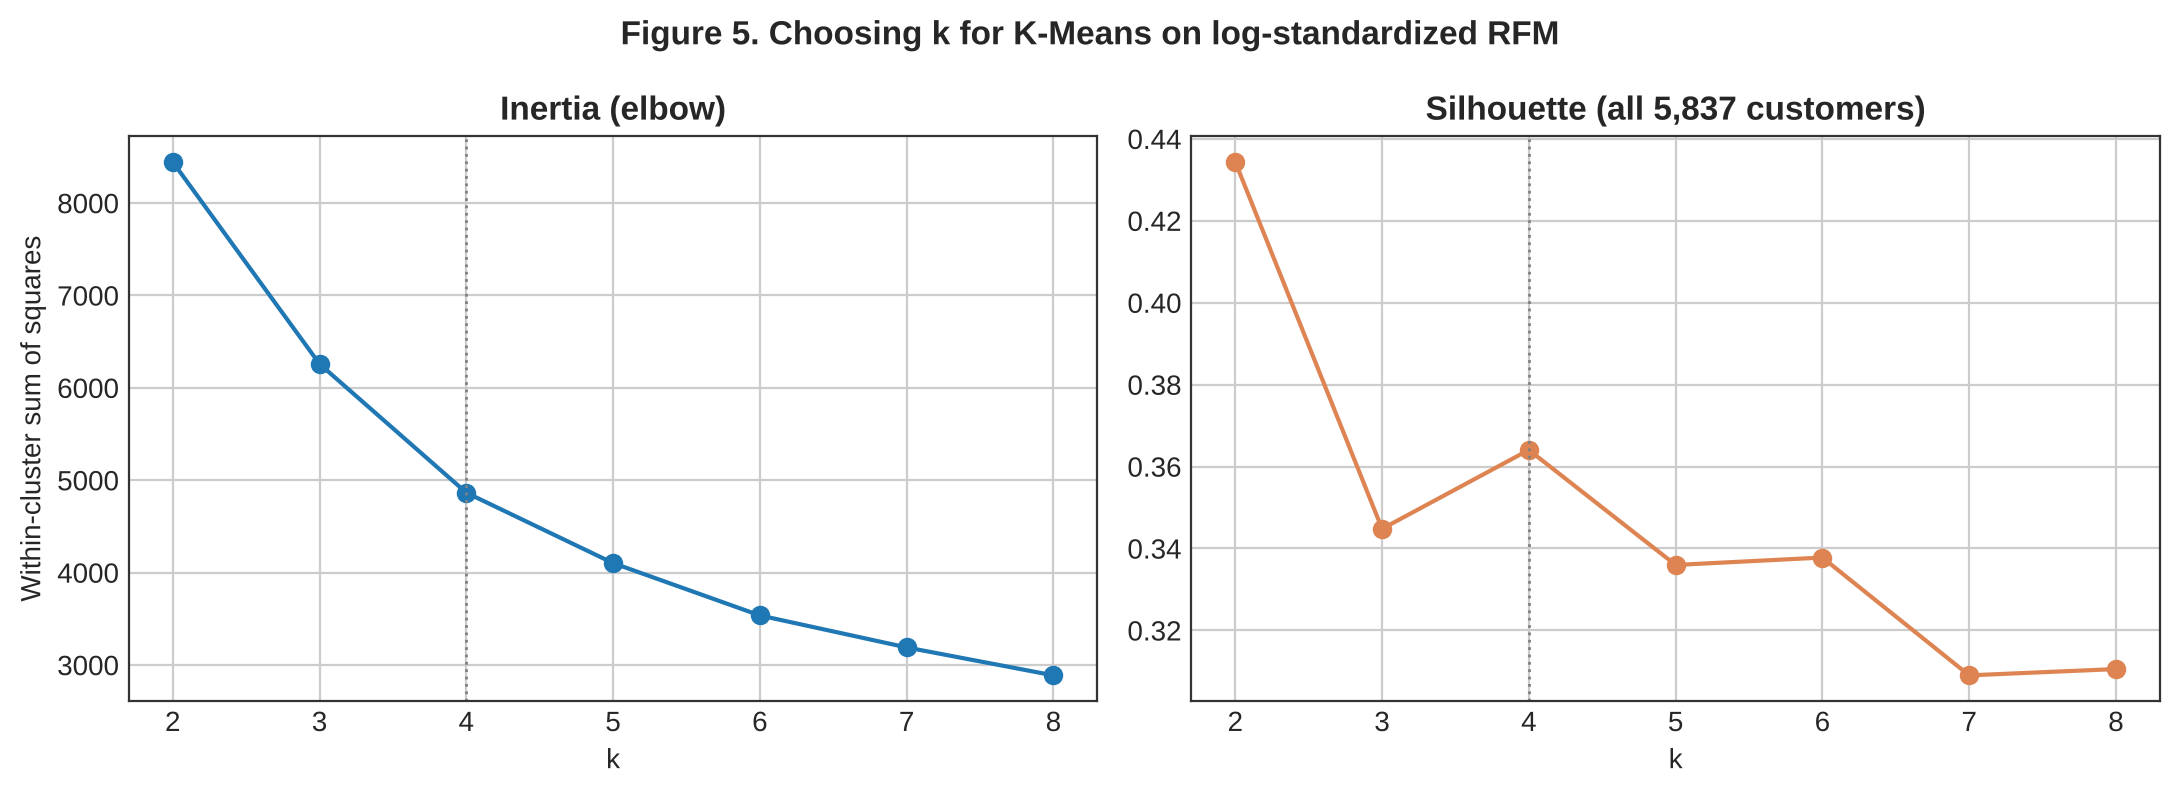

In [17]:
krows, labels_k = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEED).fit(Zs)
    labels_k[k] = km.labels_
    sizes = np.bincount(km.labels_)
    krows.append(dict(k=k, Inertia=km.inertia_, Silhouette=silhouette_score(Zs, km.labels_), SmallestCluster=int(sizes.min()),
                      SmallestPct=100 * sizes.min() / len(Zs), Sizes=sizes.tolist()))
kt = pd.DataFrame(krows).set_index('k')
display(kt.round(3))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), dpi=200)
a1.plot(kt.index, kt.Inertia, marker='o'); a1.set_title('Inertia (elbow)', fontweight='bold'); a1.set_xlabel('k'); a1.set_ylabel('Within-cluster sum of squares')
a2.plot(kt.index, kt.Silhouette, marker='o', color='#dd8452'); a2.set_title('Silhouette (all 5,837 customers)', fontweight='bold'); a2.set_xlabel('k')
for a in (a1, a2): a.axvline(4, color='grey', ls=':', lw=1)
fig.suptitle('Figure 5. Choosing k for K-Means on log-standardized RFM', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig5_k_selection.png', bbox_inches='tight'); plt.show()
R['cu_k'] = {int(k): dict(inertia=float(r.Inertia), sil=float(r.Silhouette), smallest=int(r.SmallestCluster), sizes=r.Sizes) for k, r in kt.iterrows()}

### III.3 Selected k and comparison with the other candidate
- **k = 2** has the highest silhouette, but it only splits "active/high-value" from "inactive/low-value": too coarse to assign
  different actions.
- **k = 4** has the second-highest silhouette, a clear elbow, balanced groups (no group below 15%) and separates recent occasional buyers
  from lapsed ones, which need opposite actions. **Selected: k = 4.**

In [18]:
K = 4
km = KMeans(n_clusters=K, init='k-means++', n_init=10, random_state=SEED).fit(Zs)
keep['Cluster'] = km.labels_
prof = keep.groupby('Cluster').agg(Customers=('CustomerID', 'size'), Recency_med=('Recency', 'median'), Frequency_med=('Frequency', 'median'),
                                   Monetary_med=('Monetary', 'median'), Monetary_total=('Monetary', 'sum'))
prof['% customers'] = 100 * prof.Customers / len(keep)
prof['% net revenue'] = 100 * prof.Monetary_total / keep.Monetary.sum()

names = {}
names[prof.Monetary_med.idxmax()] = 'Champions'                       # highest median net spend
names[prof.Recency_med.idxmax()] = 'Lapsed one-time buyers'            # longest time since last purchase
rest = prof.drop(list(names)).sort_values('Recency_med')
names[rest.index[0]] = 'Recent occasional buyers'                      # recent, few orders
names[rest.index[1]] = 'Cooling regulars'                              # several orders, months without buying
prof['Segment'] = prof.index.map(names)
assert prof.Segment.is_unique, prof
keep['Segment'] = keep.Cluster.map(prof.Segment)
order = prof.sort_values('Monetary_med', ascending=False).Segment.tolist()
prof = prof.set_index('Segment').loc[order]
display(prof.round(1))

# Comparison: how the k=2 solution maps onto the k=4 segments
cross = pd.crosstab(keep.Segment, labels_k[2], margins=True).loc[order + ['All']]
cross.columns = [f'k=2 group {c}' for c in cross.columns[:-1]] + ['All']
display(cross)
R['cu_profile'] = {s: {k: float(v) for k, v in r.items()} for s, r in prof.iterrows()}
R['cu_order'] = order
R['cu_k2'] = {s: [int(v) for v in r.values[:-1]] for s, r in cross.drop('All').iterrows()}
keep[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Segment']].to_csv('outputs/rfm_segments.csv', index=False)

,Customers,Recency_med,Frequency_med,Monetary_med,Monetary_total,% customers,% net revenue
Segment,,,,,,,
Champions,1226,17.0,13.0,4735.7,12202717.6,21.0,74.5
Cooling regulars,1523,188.0,4.0,1336.1,2640106.4,26.1,16.1
Recent occasional buyers,1159,24.0,3.0,725.1,955294.9,19.9,5.8
Lapsed one-time buyers,1929,401.0,1.0,254.0,584509.1,33.0,3.6


,k=2 group 0,k=2 group 1,All
Segment,,,
Champions,0,1226,1226
Cooling regulars,885,638,1523
Recent occasional buyers,573,586,1159
Lapsed one-time buyers,1929,0,1929
All,3387,2450,5837


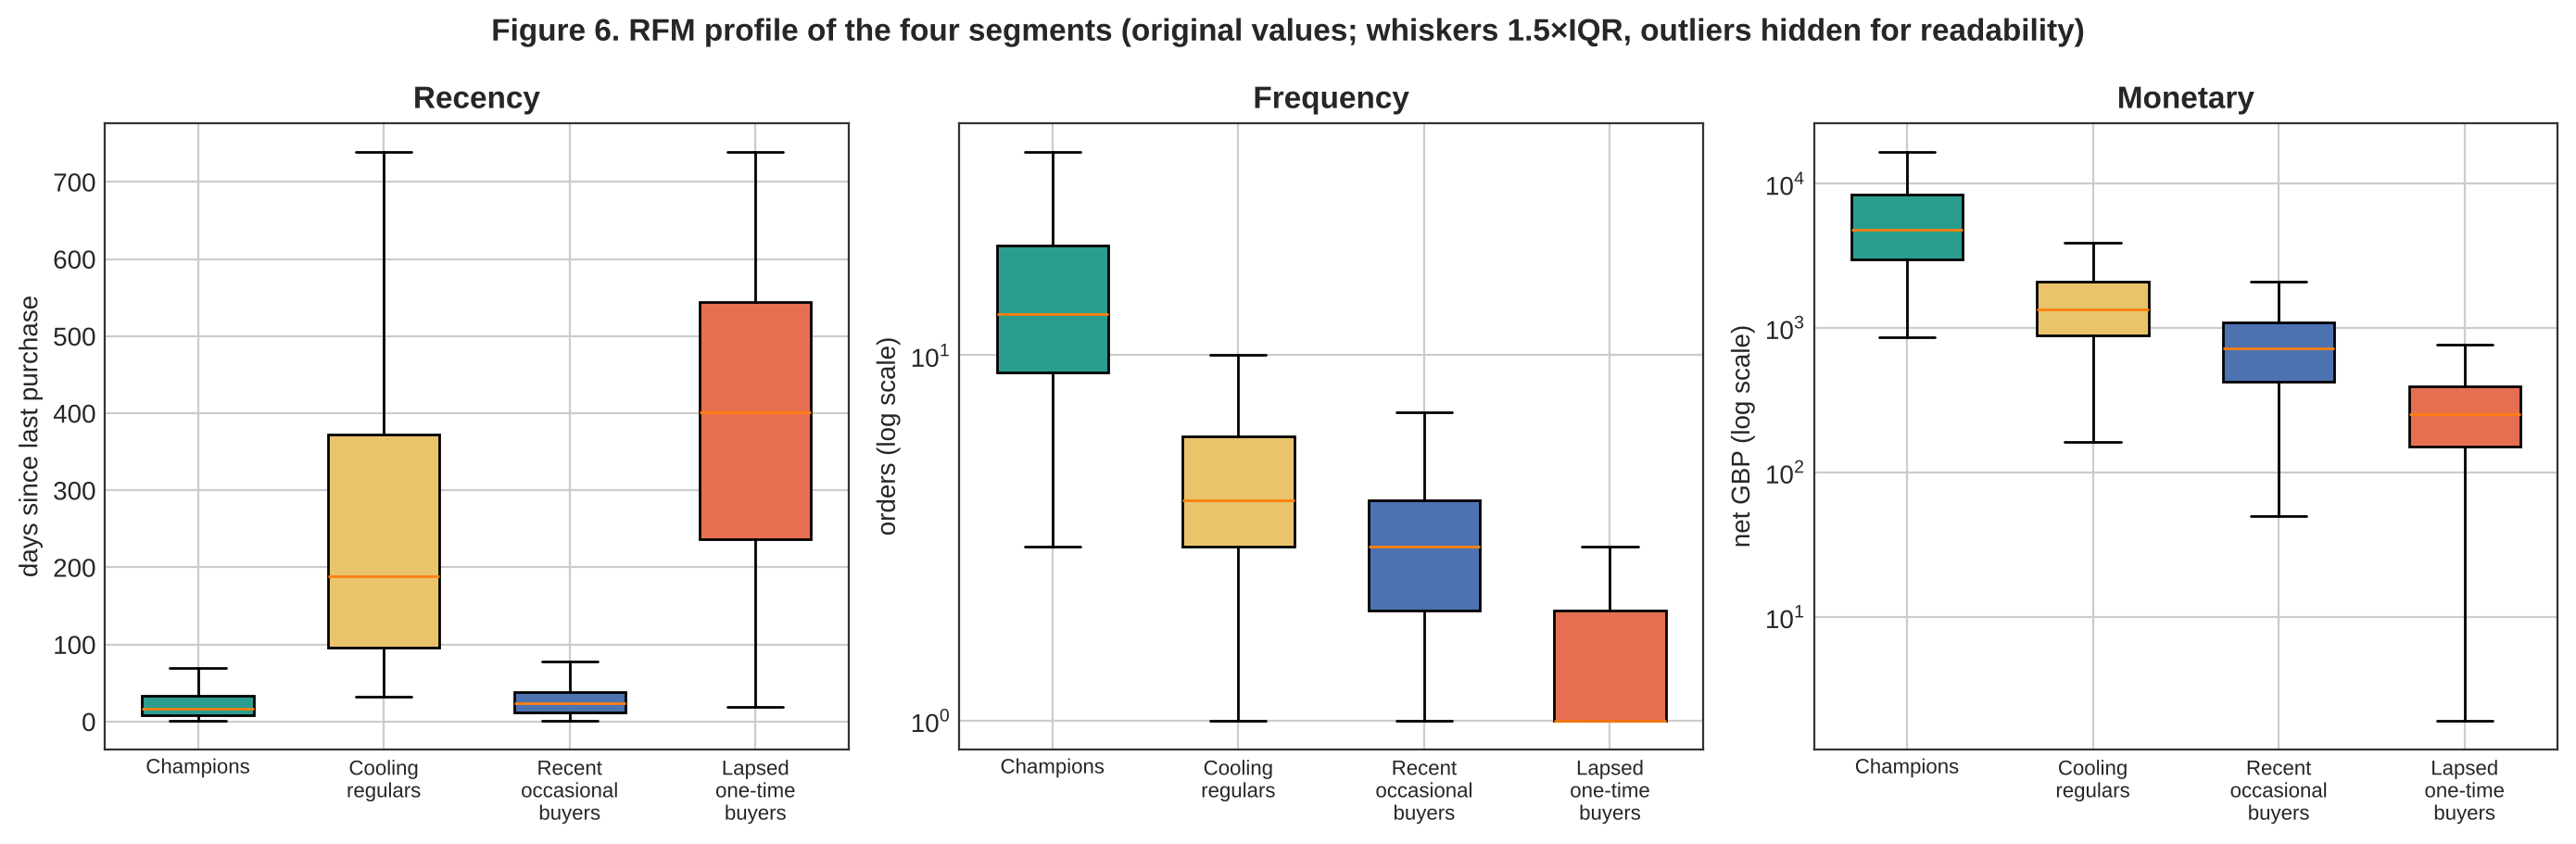

In [19]:
pal = {'Champions': '#2a9d8f', 'Cooling regulars': '#e9c46a', 'Recent occasional buyers': '#4c72b0', 'Lapsed one-time buyers': '#e76f51'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), dpi=200)
for ax, (c, unit, logy) in zip(axes, [('Recency', 'days since last purchase', False), ('Frequency', 'orders (log scale)', True), ('Monetary', 'net GBP (log scale)', True)]):
    data = [keep.loc[keep.Segment == s, c] for s in order]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    for patch, s in zip(bp['boxes'], order): patch.set_facecolor(pal[s])
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([s.replace(' ', '\n') for s in order], fontsize=8)
    ax.set_title(c, fontweight='bold'); ax.set_ylabel(unit)
    if logy: ax.set_yscale('log')
fig.suptitle('Figure 6. RFM profile of the four segments (original values; whiskers 1.5×IQR, outliers hidden for readability)', fontweight='bold')
fig.tight_layout(); fig.savefig('figures/fig6_segment_boxplots.png', bbox_inches='tight'); plt.show()

### III.4 Segment actions (descriptive segmentation, December 2011)
Each action is a test, with one follow-up indicator. RFM does not reveal motivations or profitability, so none are assumed.

| Segment | Proposed action to test | Behaviour to change | Follow-up indicator |
|---|---|---|---|
| Champions | Early access to the new season catalogue and account manager contact | Keep order cadence | Share still ordering within the next 60 days |
| Cooling regulars | Personalised "back in stock" reminder of previously bought items | Shorten the gap since the last order | Reactivation rate within 60 days |
| Recent occasional buyers | Cross-sell of complementary items based on their last order | Add one more order per quarter | % placing another order within 90 days |
| Lapsed one-time buyers | Low-cost win-back email only; no expensive incentives | Recover a small share at low cost | Reactivation rate vs random holdout |
| Net-credit accounts (41, outside K-Means) | Review with Finance before any campaign | — | Accounts reconciled |

---
# Section IV – Alignment with the project approach (A3.2 Business Understanding)
The team's Business Understanding document (`../A3.2 Business Understanding.pdf`) chose **Net Customer Value adjusted for
cancellation risk and revenue concentration (Pareto)**, for Finance and Commercial Management. Its success criteria were a forecast
that beats a simple reference by at least 20% in MAE and a prioritized customer list with a **cancellation-risk level**.
This section connects the three models above to that approach. It uses the same Route B file and the same customers as Section III.

- **Cancellation (credit) rate per customer** = − credits ÷ gross purchases over the full period (Route B, `transacciones_procesadas.csv`).
- **Risk level (business rule to review with Finance):** Low < 5% · Medium 5–10% · High ≥ 10% of gross purchases credited.
- This is a **descriptive** priority list based on observed net value up to December 2011. A customer-level projection of future
  spending (the regression proposed in A3.2) was not part of Activity 4 and remains the next step.

In [20]:
tx = pd.read_csv('../A-3-4_DataCleaning/outputs/transacciones_procesadas.csv', usecols=['CustomerID', 'LineAmount', 'MovementType'])
tx = tx[tx.CustomerID.notna()]
gc = tx.pivot_table(index='CustomerID', columns='MovementType', values='LineAmount', aggfunc='sum').fillna(0).rename(columns={'Purchase': 'GrossPurchases', 'Credit': 'Credits'})
pl = keep.set_index('CustomerID')[['Segment', 'Recency', 'Frequency', 'Monetary']].join(gc, how='left')
assert np.allclose(pl.GrossPurchases + pl.Credits, pl.Monetary, atol=0.01)      # net value = purchases + credits (Route B)
pl['CreditRate'] = -pl.Credits / pl.GrossPurchases
pl['CancellationRisk'] = pd.cut(pl.CreditRate, [-np.inf, 0.05, 0.10, np.inf], right=False, labels=['Low', 'Medium', 'High'])
pl = pl.sort_values('Monetary', ascending=False)
pl['NetValueRank'] = np.arange(1, len(pl) + 1)
pl['CumShareNet'] = pl.Monetary.cumsum() / pl.Monetary.sum()
pl['Top80'] = pl.CumShareNet <= 0.80
n80 = int(pl.Top80.sum()) + 1
print(f'Pareto: the top {n80:,} customers ({100*n80/len(pl):.1f}%) generate 80% of net revenue of the {len(pl):,} segmented customers')
print('Cancellation risk distribution:'); display(pl.CancellationRisk.value_counts().reindex(['Low', 'Medium', 'High']).to_frame('Customers').assign(Pct=lambda d: (100 * d.Customers / len(pl)).round(1)))
seg_cr = pl.groupby('Segment').agg(Customers=('Monetary', 'size'), Gross=('GrossPurchases', 'sum'), Credits=('Credits', 'sum'),
                                   AnyCredit=('CreditRate', lambda x: (x > 0).mean()), HighRisk=('CancellationRisk', lambda x: (x == 'High').sum()))
seg_cr['CreditedPctOfGross'] = -100 * seg_cr.Credits / seg_cr.Gross
seg_cr = seg_cr.loc[order]
display(seg_cr.round(3))
champ_hi = pl[(pl.Segment == 'Champions') & (pl.CancellationRisk == 'High')]
print(f'Champions with High cancellation risk: {len(champ_hi)} customers, net £{champ_hi.Monetary.sum():,.0f} '
      f'({100 * champ_hi.Monetary.sum() / pl.Monetary.sum():.1f}% of net revenue), credits £{-champ_hi.Credits.sum():,.0f}')
top80_hi = pl[pl.Top80 & (pl.CancellationRisk == 'High')]
print(f'High-risk accounts inside the Pareto top group: {len(top80_hi)} customers, net £{top80_hi.Monetary.sum():,.0f}')
out = pl.reset_index()[['NetValueRank', 'CustomerID', 'Segment', 'Monetary', 'GrossPurchases', 'Credits', 'CreditRate', 'CancellationRisk', 'Top80', 'Recency', 'Frequency']]
out.rename(columns={'Monetary': 'NetValue'}).round({'NetValue': 2, 'GrossPurchases': 2, 'Credits': 2, 'CreditRate': 4}).to_csv('outputs/customer_priority_list.csv', index=False)
print('Exported outputs/customer_priority_list.csv', out.shape)
display(out.head(10))
mae_gain = -R['fc_test']['Linear regression']['MAE vs naive %']
print(f'A3.2 technical criterion (MAE at least 20% below a simple reference): selected forecast is {mae_gain:.1f}% below the naive reference on test → '
      f"{'MET' if mae_gain >= 20 else 'NOT MET'} (daily company-level forecast; the customer-level version is the next step)")
R['a32'] = dict(pareto_n=n80, pareto_pct=float(100 * n80 / len(pl)), risk_counts={k: int(v) for k, v in pl.CancellationRisk.value_counts().items()},
                seg={sg: dict(credited_pct=float(r.CreditedPctOfGross), high=int(r.HighRisk), any_credit=float(r.AnyCredit)) for sg, r in seg_cr.iterrows()},
                champ_hi=dict(n=int(len(champ_hi)), net=float(champ_hi.Monetary.sum()), credits=float(-champ_hi.Credits.sum()), pct_net=float(100 * champ_hi.Monetary.sum() / pl.Monetary.sum())),
                top80_hi=dict(n=int(len(top80_hi)), net=float(top80_hi.Monetary.sum())), mae_gain=float(mae_gain), criterion_met=bool(mae_gain >= 20),
                total_credited_pct=float(-100 * pl.Credits.sum() / pl.GrossPurchases.sum()))

Pareto: the top 1,384 customers (23.7%) generate 80% of net revenue of the 5,837 segmented customers
Cancellation risk distribution:


,Customers,Pct
CancellationRisk,,
Low,5204,89.2
Medium,299,5.1
High,334,5.7


,Customers,Gross,Credits,AnyCredit,HighRisk,CreditedPctOfGross
Segment,,,,,,
Champions,1226,1.265731e+07,-454588.43,0.813,65,3.592
Cooling regulars,1523,2.818055e+06,-177948.81,0.525,108,6.315
Recent occasional buyers,1159,9.757924e+05,-20497.49,0.311,40,2.101
Lapsed one-time buyers,1929,6.019914e+05,-17482.27,0.162,121,2.904


Champions with High cancellation risk: 65 customers, net £767,023 (4.7% of net revenue), credits £199,020
High-risk accounts inside the Pareto top group: 75 customers, net £861,107
Exported outputs/customer_priority_list.csv (5837, 11)


,NetValueRank,CustomerID,Segment,Monetary,GrossPurchases,Credits,CreditRate,CancellationRisk,Top80,Recency,Frequency
0,1,18102.0,Champions,570380.61,580987.04,-10606.43,0.018256,Low,True,1,145
1,2,14646.0,Champions,523342.07,528602.52,-5260.45,0.009952,Low,True,2,151
2,3,14156.0,Champions,296063.44,313437.62,-17374.18,0.055431,Medium,True,10,156
3,4,14911.0,Champions,265757.91,291420.81,-25662.90,0.088061,Medium,True,2,398
4,5,17450.0,Champions,231390.55,244784.25,-13393.70,0.054716,Medium,True,9,51
5,6,13694.0,Champions,190020.84,195640.69,-5619.85,0.028725,Low,True,4,143
6,7,17511.0,Champions,168491.62,172132.87,-3641.25,0.021154,Low,True,3,60
7,8,12415.0,Champions,143269.29,144458.37,-1189.08,0.008231,Low,True,25,28
8,9,16684.0,Champions,141502.25,147142.77,-5640.52,0.038334,Low,True,5,55
9,10,15061.0,Champions,124961.98,126389.02,-1427.04,0.011291,Low,True,4,127


A3.2 technical criterion (MAE at least 20% below a simple reference): selected forecast is 37.6% below the naive reference on test → MET (daily company-level forecast; the customer-level version is the next step)


**Reading for Finance and Commercial Management.** Revenue is concentrated, as A3.2 expected: a small share of customers produces 80%
of net revenue. Most customers have no credits at all, but a small group of large accounts has a high share of purchases credited.
These are the "seemingly large accounts" A3.2 warned about; their terms should be reviewed before they receive loyalty budget.
`customer_priority_list.csv` gives Commercial a ranked list with segment, net value and cancellation-risk level.

In [21]:
with open('outputs/resultados_actividad4.json', 'w', encoding='utf-8') as fh:
    json.dump(R, fh, ensure_ascii=False, indent=1, default=str)
print('Saved outputs/resultados_actividad4.json, outputs/rfm_segments.csv and outputs/customer_priority_list.csv')

Saved outputs/resultados_actividad4.json, outputs/rfm_segments.csv and outputs/customer_priority_list.csv
